# Goal-based optimizer

Driver notebook for the user-facing model (a reworked copy of `optimizer.ipynb`, which is kept as is). The first cell holds only what a user enters: asset types, an annualized active return goal `g`, a start month and horizon `T`, a risk tolerance, `k_max`, the wealth `W` and a mode. Model settings come from the presets in `src/optimize/presets.py`, and the cell after the inputs can override any of them.

Each month-end from the start the notebook estimates the model inputs (`src.params`), solves for the portfolio (`src.optimize`), then measures the realised return over the next month. See `documentation/` for definitions. POC: MBS inputs are rough.

In [1]:
import os, sys, time
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "workbook" else os.getcwd())
sys.path.insert(0, os.getcwd())
import warnings; warnings.filterwarnings("ignore")
from dataclasses import replace
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_cleaning import config as C
from src.params import build_inputs, build_cashflows, load_data
from src.optimize.model import Settings, bands, solve_rebalance
from src.optimize import presets
from src.optimize.presets import horizon_dates, make_settings
from src.backtest import Context, RunConfig
from src.backtest import loop
from src.backtest.loop import candidates
pd.options.display.float_format = "{:,.4f}".format

## 1. Inputs

`g` is quoted per year and the model works per month, so it is converted. `T` sets the number of monthly rebalances (`N = 12 T`) from the month-end of the start month.

The mode picks the objective. `"tracking"` minimizes tracking variance plus trading cost and aims for `g` as a soft goal: a monthly shortfall below `g` is charged in the objective, so a goal out of reach is missed by as little as possible instead of being dropped. `"return"` maximizes the robust active return (expected active return minus `eps2` times its uncertainty) within the risk tolerance, and `g` is only reported against.

Risk tolerance sets three things together: the ex-ante tracking error cap, `eps2` (how much confidence the return goal needs) and a scale on the duration, key-rate, DTS and convexity tolerances. Low tolerance is tight on all three. These values are placeholders until calibration.

In [2]:
ASSET_TYPES = ["corporate", "treasury"]   # any subset
G_ANNUAL    = 0.0050        # annualized active return goal over the benchmark
START_DATE  = "2021-01"     # start month, snaps to its month-end
T_YEARS     = 4             # horizon, N = 12 * T monthly rebalances
RISK_TOL    = "medium"      # low | medium | high
K_MAX       = 150           # max number of bonds held
W           = 1_000_000     # wealth in dollars, sets the minimum lot weights
MODE        = "tracking"    # "tracking" (stay close to the benchmark, aim for g) or "return" (most return within the risk tolerance)

Advanced: `OVERRIDES` sets any `Settings` field after the presets (fields in `src/optimize/model.py`). Tolerances given here are used as is, not scaled by the risk tolerance. Leave it empty for the presets only.

In [3]:
OVERRIDES = dict(
    H=2,                    # planning dates per solve (1 = single period)
    method="heuristic",        # "heuristic" (relax then truncate) or "misocp" (binary z)
    backend="gurobipy",     # "gurobipy" (src.optimize.grb, both methods) or "cvxpy" (CLARABEL heuristic, GUROBI via cvxpy)
    tol_mode="relative",        # "flat" (one band per exposure, scaled by risk tolerance) or "relative" (each band is
                            # max(tol_rel x |benchmark exposure|, floor), per key rate, from the current benchmark)
    # tol_rel=0.10,         # relative mode: share of the benchmark exposure allowed. Preset 0.10 x risk tolerance scale,
                            # setting it here takes it as given
    time_limit=5,       # Gurobi seconds per solve, the best incumbent is used if it stops early
    mip_gap=1e-2,           # relative MIP gap at which Gurobi stops (0.03 roughly halves solve time)
    mip_focus=2,            # Gurobi MIPFocus: 0 balanced, 1 find solutions, 2 prove the bound
    mip_cand=150,           # binaries only on the mip_cand largest stage-1 weights (plus the heuristic's picks), None = all
    mip_skip_shortfall=True,  # keep the heuristic, skip the MIP, when it misses the soft goal
)
# catch-up (tracking mode): each month aim for the rate that still reaches g over the horizon, between floor and cap x g
CATCH_UP = dict(on=True, cap=2.0, floor=0.0)
N_CAND = 750               # candidate set size: the N_CAND largest eligible benchmark weights plus holdings (not a Settings field)

settings = make_settings(G_ANNUAL, RISK_TOL, K_MAX, MODE, **OVERRIDES)
print(f"{settings.backend} {settings.method}, mode {settings.objective}, risk tolerance {RISK_TOL}, k_max {settings.k_max}, H {settings.H}")
pd.Series({
    "monthly active goal (bp)": 1e4 * -settings.ret_slack,
    "TE cap (bp/yr)": 1e4 * settings.te_cap if settings.te_cap is not None else np.nan,
    "eps2": settings.eps2,
    "delta_D (yrs)": settings.delta_D,
    "tol_mode": settings.tol_mode,
    "delta_K (yrs, flat)": settings.delta_K,
    "delta_DTS (flat)": settings.delta_DTS,
    "delta_C (flat)": settings.delta_C,
    "tol_rel (relative)": settings.tol_rel,
    "gamma": settings.gamma,
    "goal_penalty": settings.goal_penalty if settings.goal_penalty is not None else np.nan,
    "cost_weight": settings.cost_weight,
}).to_frame("value")

gurobipy heuristic, mode tracking, risk tolerance medium, k_max 150, H 2


,value
monthly active goal (bp),4.1571
TE cap (bp/yr),50.0000
eps2,0.2500
delta_D (yrs),0.2500
tol_mode,relative
"delta_K (yrs, flat)",0.2000
delta_DTS (flat),0.0025
delta_C (flat),15.0000
tol_rel (relative),0.1000
gamma,"3,000.0000"


## 2. Data and rebalance dates

`load_data()` returns the bond universe, daily prices, the fitted Treasury curve and the month-end price panel. `horizon_dates` takes the first `N` month-ends from the start month and checks the window: Sigma needs 6 monthly curve changes before the first date, and the last date needs a following month-end to measure its realised return.

In [4]:
data = load_data()
ends = data.panel.index.get_level_values("month_end").unique().sort_values()
REB, END = horizon_dates(ends, START_DATE, T_YEARS)
N = len(REB)
print(f"{N} rebalances, {REB[0].date()} .. {REB[-1].date()}, last return measured to {END.date()}")
print(f"universe {len(data.universe):,} bonds, curve {data.curve.date.min().date()} .. {data.curve.date.max().date()}")

48 rebalances, 2021-01-29 .. 2024-12-31, last return measured to 2025-01-31
universe 20,619 bonds, curve 2017-08-01 .. 2025-12-31


## 3. Benchmark weights

This is index tracking, so the benchmark `b` has to match the chosen asset types. `agg_holdings_monthly` has one row per bond per month with `agg_market_value`. For month `t` we keep the selected asset types and set

`b_i = agg_market_value_i / sum over selected bonds of agg_market_value`

so the weights always sum to 1 within the selected sleeve. `build_inputs` reads `agg_weight` from the universe and then renormalizes again over the bonds that have a price at the as-of date, so we hand it a universe with `agg_weight` overwritten by the weights above (the processed universe has no such column).

In [5]:
holdings = pd.read_parquet(
    C.PROCESSED_DIR / "agg_holdings_monthly.parquet",
    columns=["holdings_date", "cusip", "asset_type", "agg_market_value"],
)
holdings["ym"] = holdings.holdings_date.dt.to_period("M")

# Filter to the selected asset types, gets used in benchmark_at() and data_for()
holdings = holdings[holdings.asset_type.isin(ASSET_TYPES)]


def benchmark_at(asof) -> pd.Series:
    """Market value weights of the selected asset types in the Agg holdings of asof's month, summing to 1."""
    h = holdings[holdings.ym == pd.Timestamp(asof).to_period("M")]
    mv = h.groupby("cusip").agg_market_value.sum()
    return mv / mv.sum()


def data_for(asof):
    """Data with the universe cut to the benchmark at asof and agg_weight set to the renormalized weights."""
    b = benchmark_at(asof)
    u = data.universe[data.universe.cusip.isin(b.index)].copy()
    u["agg_weight"] = u.cusip.map(b)
    return data._replace(universe=u)


# check at the first date: weights by asset type before and after renormalizing
h0 = pd.read_parquet(
    C.PROCESSED_DIR / "agg_holdings_monthly.parquet",
    columns=["holdings_date", "asset_type", "agg_market_value"],
)
h0 = h0[h0.holdings_date.dt.to_period("M") == REB[0].to_period("M")]
b0 = benchmark_at(REB[0])
chk = pd.DataFrame(
    {
        "full Agg": h0.groupby("asset_type").agg_market_value.sum()
        / h0.agg_market_value.sum()
    }
)
sleeve = (
    pd.Series(
        b0.values,
        index=data.universe.set_index("cusip").asset_type.reindex(b0.index).values,
    )
    .groupby(level=0)
    .sum()
)
chk["selected sleeve"] = sleeve
chk.loc["total"] = chk.sum()
print(
    f"{len(b0):,} benchmark bonds at {REB[0].date()}, matched to the universe: {b0.index.isin(data.universe.cusip).mean():.1%} of bonds"
)
chk

6,732 benchmark bonds at 2021-01-29, matched to the universe: 100.0% of bonds


,full Agg,selected sleeve
asset_type,,
corporate,0.3077,0.4268
mbs,0.2792,NaN
treasury,0.4132,0.5732
total,1.0000,1.0000


## 4. Estimation at the first date

`build_inputs(asof, W, H, data=...)` estimates everything the optimizer needs as of `asof`, using data up to that date only. With `H = 1` there is one `PeriodInputs` (planning date t). Larger `H` ages every bond forward under today's curve, giving one more `PeriodInputs` per step.

What it computes, in order:
1. Fits NSS curve parameters for `asof`, then reprices each bond off the curve plus its own spread to get key-rate durations `K`, duration `D`, spread duration, convexity `C` and `dts` (spread duration times spread).
2. Estimates the 8x8 key-rate covariance `Sigma` from monthly curve changes (Ledoit-Wolf), keeps 3 principal components, and forms the curve loadings `K Gamma Lambda^(1/2)`.
3. Adds one credit factor per corporate sector (the sector's implied common spread change each month, loading `-D_spr`). Treasuries have `D_spr = 0` and `dts = 0`, so they load on no credit factor and the DTS tolerance limits active credit exposure.
4. Estimates residual variance `psi` per bond from month-end returns net of the curve and credit factors, shrunk toward a sector prior `D^2 kappa` with a weight of 12 months.
5. Sets trading costs `c` (half the recent bid-ask), minimum lots `ell` from `W`, expected returns `mu_hat`, and benchmark weights `b` (renormalized over bonds priced at `asof`).

About a minute per date with all asset types (it refits on the full history up to `asof`).

In [6]:
asof = REB[0]
t = time.time()
P = build_inputs(asof, W, H=settings.H, data=data_for(asof))
q = P.periods[0]
print(
    f"{asof.date()}: {len(P.cusips):,} bonds, built in {time.time() - t:.0f}s, sum(b) = {P.b.sum():.6f}"
)
pd.DataFrame(
    {
        "bonds": pd.Series(P.asset_type).value_counts(),
        "b weight": pd.Series(P.b, index=P.asset_type).groupby(level=0).sum(),
        "duration": pd.Series(q.D * P.b, index=P.asset_type).groupby(level=0).sum()
        / pd.Series(P.b, index=P.asset_type).groupby(level=0).sum(),
    }
)

2021-01-29: 6,560 bonds, built in 9s, sum(b) = 1.000000


,bonds,b weight,duration
corporate,6318,0.4217,8.4853
treasury,242,0.5783,6.8871


Estimated inputs: the three curve factors (share of key-rate variance each explains), residual variance by sector, and trading costs. `psi` for bonds with under 6 residual observations is the sector prior alone.

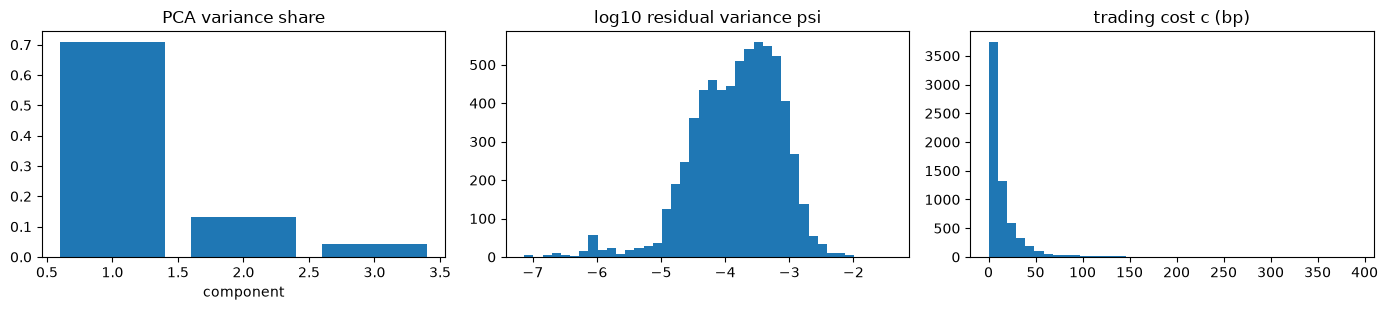

,psi median,cost median bp,stale share,bonds
industrial,0.0002,8.6407,0.0379,3748
financial,0.0001,6.6110,0.0364,1702
utility,0.0002,11.8513,0.0530,868
treasury,0.0000,2.2524,0.0000,242


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].bar(range(1, len(P.model.explained) + 1), P.model.explained)
ax[0].set_title("PCA variance share")
ax[0].set_xlabel("component")
ax[1].hist(np.log10(P.model.psi[P.model.psi > 0]), bins=40)
ax[1].set_title("log10 residual variance psi")
ax[2].hist(1e4 * P.c, bins=40)
ax[2].set_title("trading cost c (bp)")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        "psi median": pd.Series(P.model.psi, index=P.sector).groupby(level=0).median(),
        "cost median bp": pd.Series(1e4 * P.c, index=P.sector)
        .groupby(level=0)
        .median(),
        "stale share": pd.Series(P.stale, index=P.sector).groupby(level=0).mean(),
        "bonds": pd.Series(P.sector).value_counts(),
    }
).sort_values("bonds", ascending=False)

## 5. Solve at the first date

`solve_rebalance(P, S, x_init, settings)` solves one of two objectives over the same constraints. The constraints are: fully invested, no shorting, active weight caps, tolerances on active duration, DTS, convexity and each key-rate duration, and the ex-ante tracking error cap.
- `"tracking"`: minimize `gamma * (tracking variance) + trading cost + goal_penalty * shortfall`. The shortfall is how far the robust active return (expected active return minus `eps2 * ||Theta^(1/2) (x - b)||`) falls below the monthly goal.
- `"return"`: minimize `-(robust active return) + cost_weight * trading cost + gamma * (tracking variance)`, with a small `gamma` as a tie-breaker. `cost_weight` below 1 spreads the one-off trading cost over several months, otherwise a single month of extra return never pays for a trade.

There are two ways to enforce the cardinality limit `k_max` and the minimum lots, picked by `method`. `"heuristic"`: stage 1 solves the relaxation, stage 2 keeps the `k_max` largest weights, forces them to at least the minimum lot, and re-solves. `"misocp"` (Gurobi): one solve with a binary `z_i` per bond, `x_i <= z_i`, `x_i >= ell_i z_i`, `sum z <= k_max`. Gurobi stops at `time_limit` seconds and uses its best incumbent, so status `user_limit` means a feasible but not proven optimal portfolio. If the model is infeasible, the tolerances and the TE cap are widened together (x2, x4, x8), and `delta_scale` reports this. The goal is soft, so it is never dropped.

Inputs the notebook prepares:
- `S`: candidate set, the `N_CAND` largest benchmark weights among eligible bonds (not stale, not exiting, minimum lot small enough that `k_max` lots fit) plus current holdings. Tracking is still measured against the full benchmark.
- `x_init`: current holdings. Zero at the first date (we start in cash, so the first trade pays full cost).

In [8]:
Pf = P
S, x_init = candidates(Pf, {}, settings.k_max, settings.H, N_CAND, settings.max_active_w)
t = time.time()

# Solve the problem at the first rebalance date
sol = solve_rebalance(Pf, S, x_init, settings)
print(f"status {sol.status}, solved in {time.time() - t:.1f}s, |S| = {len(S)}")
print(
    f"held {int((sol.x[0] > 1e-6).sum())} bonds (k_max {settings.k_max}), tolerance scale {sol.delta_scale:g}, "
    f"robust active return {1e4 * sol.robust_active:+.2f} bp/mo vs goal {1e4 * -settings.ret_slack:.2f}, shortfall {1e4 * sol.shortfall:.2f} bp/mo"
)

status optimal, solved in 1.0s, |S| = 750
held 150 bonds (k_max 150), tolerance scale 1, robust active return +4.16 bp/mo vs goal 4.16, shortfall 0.00 bp/mo


Result at the first date: every constraint of the model at the date-t portfolio, with its bounds (tolerances and TE cap already multiplied by the tolerance scale), then the largest holdings. Active weights are `a = x - b` over all benchmark bonds (bonds outside `S` are at zero, so their active weight is `-b`). The return goal row is the robust active return minus the goal. With a soft goal it can be negative (a shortfall), so it has no lower bound.

In [9]:
x0 = sol.x[0] / sol.x[0].sum()
a = -q.b_hat.copy()
a[S] += x0
s_, sc = settings, sol.delta_scale
bd = bands(q, s_)   # tolerance half-widths at h = 0 (flat or relative to the benchmark)
held = x0 > 1e-9
cap = q.b_hat[S] + s_.max_active_w if s_.max_active_w is not None else np.full(len(S), np.inf)
d_x = x0 - x_init

# (value, lower, upper) for every constraint in solve_rebalance, at h = 0
rows = {
    "budget: sum x": (x0.sum(), 1, 1),
    "no shorting: min x": (x0.min(), 0, np.inf),
    "active weight cap: max(x - b - cap)": ((x0 - cap).max(), -np.inf, 0),
    "exits: weight in exiting bonds": (x0[q.exits[S]].sum(), 0, 0),
    "cardinality: bonds held": (int(held.sum()), 0, s_.k_max),
    "min lot: min x / ell over held": ((x0[held] / q.ell[S][held]).min(), 1, np.inf),
    "trades: turnover, sum |x - x_init|": (np.abs(d_x).sum(), 0, np.inf),
    "active duration (yrs)": (q.D @ a, -bd["D"] * sc, bd["D"] * sc),
    "active DTS": (q.dts @ a, -bd["DTS"] * sc, bd["DTS"] * sc),
    "active convexity": (q.C @ a, -bd["C"] * sc, bd["C"] * sc),
}
for tenor, v, d in zip(C.KEY_RATES, q.K.T @ a, bd["K"]):
    rows[f"active KRD {tenor.lower()}"] = (v, -d * sc, d * sc)
if s_.te_cap is not None:
    rows["ex-ante TE (bp/yr)"] = (1e4 * np.sqrt(12 * sol.track_var), 0, 1e4 * s_.te_cap * sc)
# robust active return mu'a - eps2 ||Theta^(1/2) a|| minus the monthly goal. Bounded below by 0 only for a hard goal
hard = s_.objective == "tracking" and s_.goal_penalty is None and not sol.return_goal_dropped
rows["return goal margin: robust active - goal (bp/mo)"] = (
    1e4 * (sol.robust_active + s_.ret_slack), 0 if hard else -np.inf, np.inf)

tol = pd.DataFrame(rows, index=["value", "lower", "upper"]).T
tol["ok"] = (tol.value >= tol.lower - 1e-6) & (tol.value <= tol.upper + 1e-6)
# binding: value within solver tolerance of either bound (equalities always bind)
tol["binding"] = np.isclose(tol.value, tol.lower, rtol=1e-4, atol=1e-6) | np.isclose(tol.value, tol.upper, rtol=1e-4, atol=1e-6)
print(
    f"tolerance scale {sc:g}, goal shortfall {1e4 * sol.shortfall:.2f} bp/mo, "
    f"forecast tracking error {1e4 * np.sqrt(sol.track_var * 12):.1f} bp/yr, overlap with benchmark {1 - 0.5 * np.abs(a).sum():.1%}"
)
top = (
    pd.DataFrame(
        {"cusip": Pf.cusips[S], "sector": Pf.sector[S], "x": x0, "b": q.b_hat[S]}
    )
    .assign(active=lambda d: d.x - d.b)
    .merge(
        data.universe[
            [
                "cusip",
                "name",
            ]
        ],
        how="left",
        on="cusip",
    )
)
display(tol)
top[top.x > 1e-6].sort_values("x", ascending=False).head(10)

tolerance scale 1, goal shortfall 0.00 bp/mo, forecast tracking error 30.8 bp/yr, overlap with benchmark 10.8%


,value,lower,upper,ok,binding
budget: sum x,1.0000,1.0000,1.0000,True,True
no shorting: min x,0.0000,0.0000,inf,True,True
active weight cap: max(x - b - cap),-0.0000,-inf,0.0000,True,True
exits: weight in exiting bonds,0.0000,0.0000,0.0000,True,True
cardinality: bonds held,150.0000,0.0000,150.0000,True,True
min lot: min x / ell over held,1.0000,1.0000,inf,True,True
"trades: turnover, sum |x - x_init|",1.0000,0.0000,inf,True,False
active duration (yrs),-0.0404,-0.2500,0.2500,True,False
active DTS,-0.0037,-0.0043,0.0043,True,False
active convexity,0.4424,-11.4013,11.4013,True,False


,cusip,sector,x,b,active,name
585,912810SQ2,treasury,0.0215,0.0047,0.0168,TREASURY BOND
467,92343VER1,industrial,0.0205,0.0005,0.0200,VERIZON COMMUNICATIONS INC
465,92343VEA8,industrial,0.0203,0.0003,0.0200,VERIZON COMMUNICATIONS INC
461,92343VDD3,industrial,0.0202,0.0002,0.0200,VERIZON COMMUNICATIONS INC
19,00287YBM0,industrial,0.0202,0.0002,0.0200,ABBVIE INC
185,172967LD1,financial,0.0202,0.0002,0.0200,CITIGROUP INC
340,58013MFP4,industrial,0.0202,0.0002,0.0200,MCDONALDS CORPORATION MTN
190,172967LW9,financial,0.0202,0.0002,0.0200,CITIGROUP INC
105,06051GHG7,financial,0.0202,0.0002,0.0200,BANK OF AMERICA CORP MTN
448,89153VAQ2,industrial,0.0202,0.0002,0.0200,TOTALENERGIES CAPITAL INTERNATIONA


## 6. Roll forward over the horizon

The loop repeats steps 4 and 5 at every rebalance date. At each date:
1. Re-estimate (`build_inputs`) using only data up to that date, with the benchmark for that month.
2. Sell held bonds that left the benchmark (or have no price) at half the bid-ask, keeping the proceeds as cash. Solve starting from the remaining holdings, drifted by realised returns, so reinvesting the cash pays the buy cost.
3. Execute the date-t trades, paying `c' |trades|`.
4. Measure the realised return to the next month-end with `realised_returns` (month-end prices plus coupons paid; a bond with a stale price at either end takes its model return `mu_hat`).

Catch-up (tracking mode, `CATCH_UP`): `g` is a goal over the whole horizon, so before each solve the monthly goal is reset to the rate that still reaches it, `g_req = ((1 + g_m)^N / A)^(1 / months left) - 1`, where `A` is the cumulative active growth so far. It is clipped to `[floor, cap * g_m]`: behind the goal asks for at most twice the original rate, and ahead of it eases off to no less than the benchmark. `goal_req` records the rate each month aimed for, and `shortfall` is measured against it.

Active return is the net portfolio return minus the benchmark return `b_hat' r`. Params are cached in memory by date, so re-running with another risk level or `k_max` skips the slow estimation (the cache is keyed by `H` and asset types, so change either and clear `PARAMS`).

In [10]:
# shared data, benchmark, cash flow table and the on-disk params cache (src/backtest/cache.py)
ctx = Context(RunConfig(asset_types=tuple(ASSET_TYPES), start=START_DATE, T=T_YEARS, W=W))


def rolling(s: Settings) -> pd.DataFrame:
    """The loop lives in src/backtest/loop.py. Params are cached on disk by asset types, H, W and source."""
    return loop.run(s, ctx.dates, ctx.ends, ctx.data, ctx.data_for, ctx.table, ctx.cache(s.H, W), N_CAND,
                    CATCH_UP).monthly


res = rolling(settings)

2021-01-29 active  -15.7 bp  cost   2.3 bp  hold 150  TE  30.8 bp/yr  goal  4.16  shortfall  0.00 bp  scale 1  solve  0.2s
2021-02-26 active  -10.2 bp  cost   1.4 bp  hold 150  TE  21.2 bp/yr  goal  4.59  shortfall  0.00 bp  scale 1  solve  0.2s
2021-03-31 active  +11.9 bp  cost   0.5 bp  hold 150  TE  19.7 bp/yr  goal  4.91  shortfall  0.00 bp  scale 1  solve  0.3s
2021-04-30 active   -3.5 bp  cost   0.5 bp  hold 150  TE  20.9 bp/yr  goal  4.76  shortfall  0.00 bp  scale 1  solve  0.2s
2021-05-28 active   -3.5 bp  cost   0.2 bp  hold 150  TE  20.4 bp/yr  goal  4.95  shortfall  0.00 bp  scale 1  solve  0.2s
2021-06-30 active   +2.9 bp  cost   0.6 bp  hold 150  TE  22.8 bp/yr  goal  5.14  shortfall  0.00 bp  scale 1  solve  0.2s
2021-07-30 active  +12.1 bp  cost   0.4 bp  hold 150  TE  23.4 bp/yr  goal  5.20  shortfall  0.00 bp  scale 1  solve  0.3s
2021-08-31 active  +13.9 bp  cost   0.3 bp  hold 150  TE  20.9 bp/yr  goal  5.03  shortfall  0.00 bp  scale 1  solve  0.2s
2021-09-30 activ

## 7. Results

Annualized active return is compared with the goal `g`. Realised tracking error is the annualized standard deviation of monthly active returns (needs several months to mean much), shown next to the average ex-ante forecast and the cap. Shortfall months are those where the forecast robust active return was below the goal, i.e. the goal was out of reach under the risk tolerance and `k_max`.

,value
months,48.0000
cum portfolio,-0.0548
cum benchmark,-0.0734
"active return, annualized",0.0050
goal g,0.0050
"tracking error, annualized",0.0038
avg turnover,0.1423
avg cost bp,0.7347
avg holdings,150.0000
avg forecast TE,0.0020


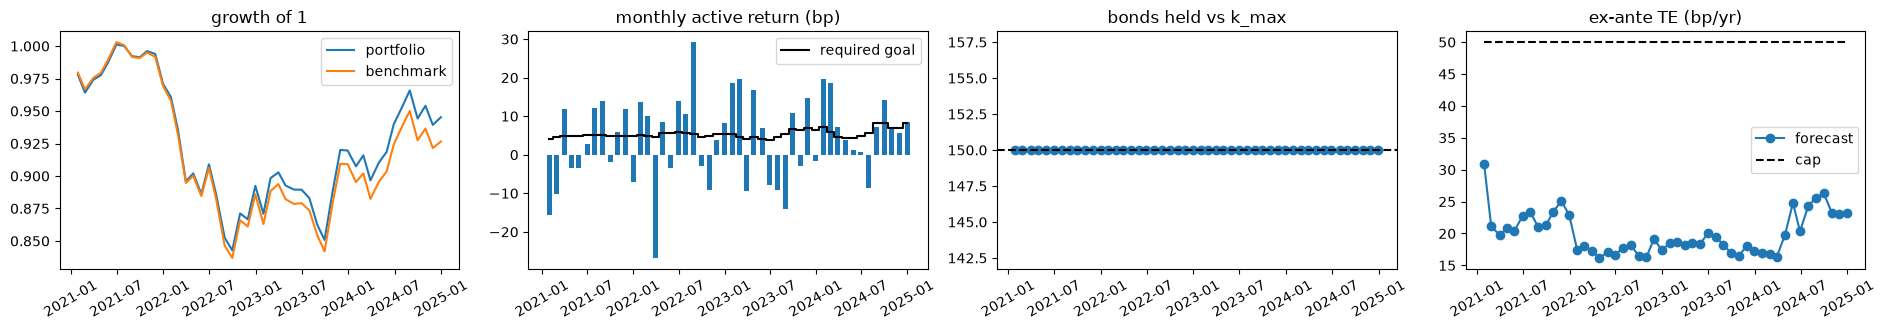

,ret_port,ret_bench,active,cost,exit_cost,turnover,n_hold,n_bonds,te_fcst_ann,te_cap_ann,act_D,goal_req,robust_active,shortfall,goal_dropped,mip_skipped,delta_scale,status,seconds
date,,,,,,,,,,,,,,,,,,,
2021-01-29,-0.0220,-0.0204,-0.0016,0.0002,0.0000,1.0000,150,6560,0.0031,0.0050,-0.0404,0.0004,0.0004,0.0000,False,False,1.0000,optimal,0.2022
2021-02-26,-0.0142,-0.0132,-0.0010,0.0001,0.0000,0.2409,150,6612,0.0021,0.0050,0.0025,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2014
2021-03-31,0.0103,0.0092,0.0012,0.0000,0.0000,0.1321,150,6555,0.0020,0.0050,0.0028,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2555
2021-04-30,0.0036,0.0040,-0.0003,0.0001,0.0000,0.1285,150,6650,0.0021,0.0050,0.0081,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2484
2021-05-28,0.0100,0.0103,-0.0004,0.0000,0.0000,0.0831,150,6680,0.0020,0.0050,0.0211,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.1956
2021-06-30,0.0139,0.0137,0.0003,0.0001,0.0000,0.0967,150,6726,0.0023,0.0050,0.0157,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2043
2021-07-30,-0.0011,-0.0023,0.0012,0.0000,0.0000,0.0828,150,6732,0.0023,0.0050,0.0155,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2621
2021-08-31,-0.0079,-0.0093,0.0014,0.0000,0.0000,0.0860,150,6778,0.0021,0.0050,0.0174,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2093
2021-09-30,-0.0008,-0.0007,-0.0002,0.0000,0.0000,0.0767,150,6789,0.0021,0.0050,0.0229,0.0005,0.0005,0.0000,False,False,1.0000,optimal,0.2261


In [11]:
def summary(res: pd.DataFrame, g=G_ANNUAL) -> pd.Series:
    n = len(res)
    cp_, cb = (1 + res.ret_port).prod(), (1 + res.ret_bench).prod()
    return pd.Series(
        {
            "months": n,
            "cum portfolio": cp_ - 1,
            "cum benchmark": cb - 1,
            "active return, annualized": (cp_ / cb) ** (12 / n) - 1,
            "goal g": g,
            "tracking error, annualized": (
                res.active.std(ddof=1) * np.sqrt(12) if n > 1 else np.nan
            ),
            "avg turnover": res.turnover.mean(),
            "avg cost bp": 1e4 * res.cost.mean(),
            "avg holdings": res.n_hold.mean(),
            "avg forecast TE": res.te_fcst_ann.mean(),
            "TE cap": res.te_cap_ann.iloc[0] if len(res) else np.nan,
            "avg forecast robust active, annualized": 12 * res.robust_active.mean(),
            "avg required goal, annualized": (1 + res.goal_req.mean()) ** 12 - 1,
            "goal shortfall months": int((res.shortfall > 1e-6).sum()),
            "avg shortfall bp/mo": 1e4 * res.shortfall.mean(),
            "tolerance widened months": int((res.delta_scale > 1).sum()),
            "MIP skipped months (heuristic kept)": int(res.mip_skipped.sum()),
            "avg solve seconds": res.seconds.mean(),
        }
    )


display(summary(res).to_frame("value"))
fig, ax = plt.subplots(1, 4, figsize=(19, 3.4))
ax[0].plot((1 + res.ret_port).cumprod(), label="portfolio")
ax[0].plot((1 + res.ret_bench).cumprod(), label="benchmark")
ax[0].set_title("growth of 1")
ax[0].legend()
ax[1].bar(res.index, 1e4 * res.active, width=20)
ax[1].step(res.index, 1e4 * res.goal_req, where="mid", color="k", label="required goal")
ax[1].legend()
ax[1].set_title("monthly active return (bp)")
ax[2].plot(res.n_hold, marker="o")
ax[2].axhline(settings.k_max, color="k", ls="--")
ax[2].set_title("bonds held vs k_max")
ax[3].plot(1e4 * res.te_fcst_ann, marker="o", label="forecast")
ax[3].plot(1e4 * res.te_cap_ann, color="k", ls="--", label="cap")
ax[3].set_title("ex-ante TE (bp/yr)")
ax[3].legend()
for a_ in ax:
    a_.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
res

,value
months,24.0000
cum portfolio,0.1549
cum benchmark,0.1524
"active return, annualized",0.0011
goal g,0.0050
"tracking error, annualized",0.0135
avg turnover,0.1090
avg cost bp,0.7849
avg holdings,147.0833
avg forecast TE,0.0013


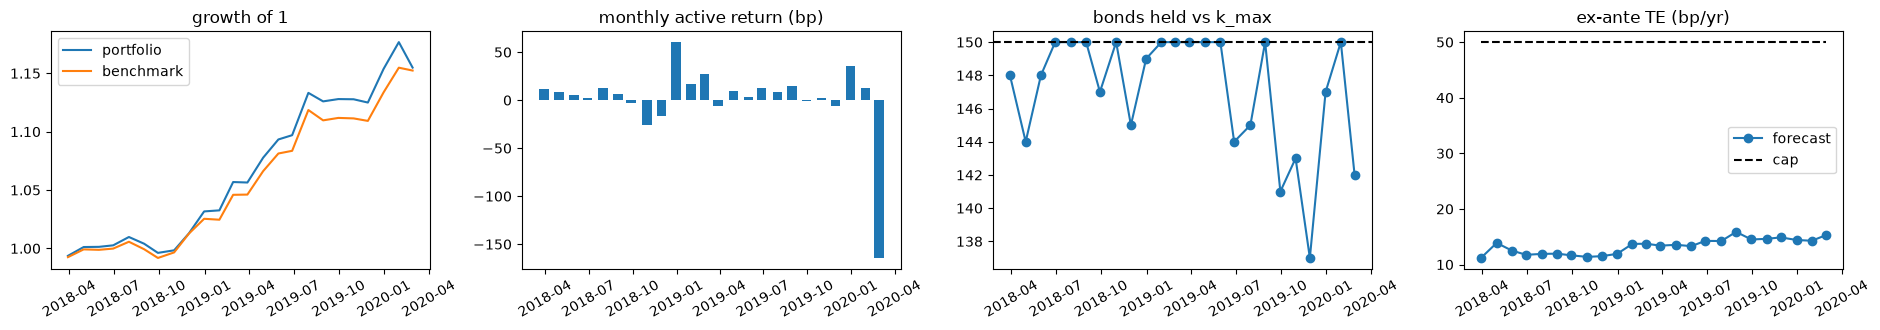

,ret_port,ret_bench,active,cost,exit_cost,turnover,n_hold,n_bonds,te_fcst_ann,act_D,te_cap_ann,robust_active,shortfall,goal_dropped,mip_skipped,delta_scale,status
date,,,,,,,,,,,,,,,,,
2018-03-29,-0.0064,-0.0075,0.0011,0.0004,0.0000,1.0000,148,5313,0.0011,0.0002,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-04-30,0.0076,0.0067,0.0009,0.0006,0.0000,0.2337,144,5352,0.0014,0.0099,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-05-31,0.0002,-0.0004,0.0005,0.0000,0.0000,0.0518,148,5381,0.0013,-0.0037,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-06-29,0.0013,0.0011,0.0002,0.0000,0.0000,0.0610,150,5411,0.0012,0.0050,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-07-31,0.0071,0.0059,0.0013,0.0000,0.0000,0.0797,150,5455,0.0012,0.0016,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-08-31,-0.0057,-0.0064,0.0007,0.0000,0.0000,0.0290,150,5477,0.0012,-0.0036,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-09-28,-0.0078,-0.0075,-0.0003,0.0001,0.0000,0.0561,147,5505,0.0012,0.0021,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-10-31,0.0022,0.0048,-0.0026,0.0000,0.0000,0.0250,150,5502,0.0011,0.0013,0.0050,0.0004,0.0000,False,False,1.0000,optimal
2018-11-30,0.0145,0.0161,-0.0016,0.0000,0.0000,0.0676,145,5519,0.0012,-0.0018,0.0050,0.0005,0.0000,False,False,1.0000,optimal


In [ ]:
def summary(res: pd.DataFrame, g=G_ANNUAL) -> pd.Series:
    n = len(res)
    cp_, cb = (1 + res.ret_port).prod(), (1 + res.ret_bench).prod()
    return pd.Series(
        {
            "months": n,
            "cum portfolio": cp_ - 1,
            "cum benchmark": cb - 1,
            "active return, annualized": (cp_ / cb) ** (12 / n) - 1,
            "goal g": g,
            "tracking error, annualized": (
                res.active.std(ddof=1) * np.sqrt(12) if n > 1 else np.nan
            ),
            "avg turnover": res.turnover.mean(),
            "avg cost bp": 1e4 * res.cost.mean(),
            "avg holdings": res.n_hold.mean(),
            "avg forecast TE": res.te_fcst_ann.mean(),
            "TE cap": res.te_cap_ann.iloc[0] if len(res) else np.nan,
            "avg forecast robust active, annualized": 12 * res.robust_active.mean(),
            "avg required goal, annualized": (1 + res.goal_req.mean()) ** 12 - 1,
            "goal shortfall months": int((res.shortfall > 1e-6).sum()),
            "avg shortfall bp/mo": 1e4 * res.shortfall.mean(),
            "tolerance widened months": int((res.delta_scale > 1).sum()),
            "MIP skipped months (heuristic kept)": int(res.mip_skipped.sum()),
            "avg solve seconds": res.seconds.mean(),
        }
    )


display(summary(res).to_frame("value"))
fig, ax = plt.subplots(1, 4, figsize=(19, 3.4))
ax[0].plot((1 + res.ret_port).cumprod(), label="portfolio")
ax[0].plot((1 + res.ret_bench).cumprod(), label="benchmark")
ax[0].set_title("growth of 1")
ax[0].legend()
ax[1].bar(res.index, 1e4 * res.active, width=20)
ax[1].step(res.index, 1e4 * res.goal_req, where="mid", color="k", label="required goal")
ax[1].legend()
ax[1].set_title("monthly active return (bp)")
ax[2].plot(res.n_hold, marker="o")
ax[2].axhline(settings.k_max, color="k", ls="--")
ax[2].set_title("bonds held vs k_max")
ax[3].plot(1e4 * res.te_fcst_ann, marker="o", label="forecast")
ax[3].plot(1e4 * res.te_cap_ann, color="k", ls="--", label="cap")
ax[3].set_title("ex-ante TE (bp/yr)")
ax[3].legend()
for a_ in ax:
    a_.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
res

## 8. Sensitivity to risk tolerance and mode

Re-runs the loop for each risk tolerance and mode at the inputs above, reusing the cached estimates. Each run is a solve per month, so keep the grid small.

In [ ]:
out = {}
for rt in presets.RISK_TOL:
    for mode in presets.MODES:
        try:
            s_rt = make_settings(G_ANNUAL, rt, K_MAX, mode, **OVERRIDES)
        except ValueError as e:     # goal above the information ratio ceiling for this risk tolerance
            print(f"{rt} {mode}: {e}")
            continue
        out[(rt, mode)] = summary(rolling(s_rt))
pd.DataFrame(out).T.rename_axis(["risk tolerance", "mode"])